# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:Sadia Fatima**
- **Student ID:023-24-0213**
- **Section:G**
- **GitHub:https://github.com/Sadia-Farooque/Machine_Learning.git**
- **Kaggle:https://www.kaggle.com/anamfarooque**
- **Dataset:** Telco Customer Churn (Kaggle)

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

df = pd.read_csv('clean_churn.csv')
print("Shape:", df.shape)


df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Missing TotalCharges:", df['TotalCharges'].isna().sum())

df['TotalCharges'] = df['TotalCharges'].fillna(0)


# clean_churn.csv already has customerID removed, so only drop it if present
df = df.drop(columns=['customerID'], errors='ignore')
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(df['Churn'].value_counts(normalize=True).round(3))
df.head()

Shape: (7043, 20)
Missing TotalCharges: 0
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [ ]:
# YOUR CODE HERE

from sklearn.model_selection import train_test_split

X = pd.get_dummies(df.drop(columns=['Churn']), drop_first=True).astype(float)
y = df['Churn']


RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Features:", X.shape[1])
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train/test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Features: 30
Train: (5634, 30)  Test: (1409, 30)
Churn rate train/test: 0.265 / 0.265


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [ ]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


start = time.time()
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter('always')
    svm_raw = SVC(kernel='linear', random_state=42, max_iter=1_000_000)
    svm_raw.fit(X_train, y_train)
raw_time = time.time() - start

y_pred_raw = svm_raw.predict(X_test)
print(f"Training time : {raw_time:.2f} s")
print(f"Accuracy      : {accuracy_score(y_test, y_pred_raw):.4f}")
print(f"F1-score      : {f1_score(y_test, y_pred_raw):.4f}")
print(f"Support vecs  : {svm_raw.support_.shape[0]}")
print("Warnings      :", [str(w.message)[:90] for w in w_raw] or "None")

Training time : 42.03 s
Accuracy      : 0.5997
F1-score      : 0.4891
Support vecs  : 1203
Warnings      : ['Solver terminated early (max_iter=1000000).  Consider pre-processing your data with Standa']


In [ ]:
# YOUR CODE HERE — scaled linear SVM

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

start = time.time()
with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter('always')
    svm_scaled = SVC(kernel='linear', random_state=42, max_iter=1_000_000)
    svm_scaled.fit(X_train_s, y_train)
scaled_time = time.time() - start

y_pred_s = svm_scaled.predict(X_test_s)
print(f"Training time : {scaled_time:.2f} s")
print(f"Accuracy      : {accuracy_score(y_test, y_pred_s):.4f}")
print(f"F1-score      : {f1_score(y_test, y_pred_s):.4f}")
print(f"Support vecs  : {svm_scaled.support_.shape[0]}")
print("Warnings      :", [str(w.message)[:90] for w in w_s] or "None")

pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, y_pred_raw), accuracy_score(y_test, y_pred_s)],
    'F1-score': [f1_score(y_test, y_pred_raw), f1_score(y_test, y_pred_s)],
    'Train time (s)': [raw_time, scaled_time],
    'Warnings': [len(w_raw), len(w_s)]
}, index=['Unscaled', 'Scaled']).round(4)

Training time : 2.22 s
Accuracy      : 0.7892
F1-score      : 0.5714
Support vecs  : 2569
Warnings      : None


,Accuracy,F1-score,Train time (s),Warnings
Unscaled,0.5997,0.4891,42.0289,1
Scaled,0.7892,0.5714,2.2247,0


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:*
The difference was huge. The unscaled model got only 59.97% accuracy and an F1 of 0.4891. It took about 42 seconds to train and still did not finish properly sklearn gave a warning: Solver terminated early (max_iter=1000000). Consider pre-processing your data with StandardScaler. The scaled model got 78.92% accuracy and an F1 of 0.5714, trained in about 2 seconds, and gave no warnings. So scaling made the model about 20x faster and about 20 accuracy points better.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:*
SVM finds the boundary by measuring distances between points. In our data, TotalCharges goes up to around 8,000 and MonthlyCharges up to around 120, while all the dummy columns are just 0 or 1. So when distances are computed, TotalCharges completely takes over and the other 25+ columns barely count. The optimizer has to work with very big numbers on one axis and tiny ones on the rest, so the problem becomes badly shaped and it keeps taking tiny steps without settling that is why it hit the iteration limit. Since it stopped early, the boundary it gave back is basically a half-finished one, which explains the poor accuracy.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:*
From here on I will use the scaled data (X_train_s, X_test_s) for every SVM. It is more accurate, much faster, and it actually converges. The scaler is fitted on the training set only, so no information from the test set leaks in.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
kernel_models = {}
rows = []
for k in ['linear', 'rbf', 'poly']:
    start = time.time()
    model = SVC(kernel=k, random_state=42)
    model.fit(X_train_s, y_train)
    t = time.time() - start
    pred = model.predict(X_test_s)
    kernel_models[k] = model
    rows.append({
        'Kernel': k,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-score': f1_score(y_test, pred),
        'Support Vectors': model.support_.shape[0],
        'SV per class (0,1)': tuple(model.n_support_),
        'Train time (s)': round(t, 2)
    })
    print(f"{k} done")

linear done


rbf done


poly done


In [6]:
# YOUR CODE HERE — comparison table
kernel_df = pd.DataFrame(rows).set_index('Kernel').round(4)
kernel_df

,Accuracy,Precision,Recall,F1-score,Support Vectors,"SV per class (0,1)",Train time (s)
Kernel,,,,,,,
linear,0.7892,0.6207,0.5294,0.5714,2569,"(1287, 1282)",1.99
rbf,0.7928,0.6444,0.4893,0.5562,2661,"(1432, 1229)",1.73
poly,0.7892,0.6421,0.4652,0.5395,2739,"(1485, 1254)",1.49


Best kernel on F1: linear


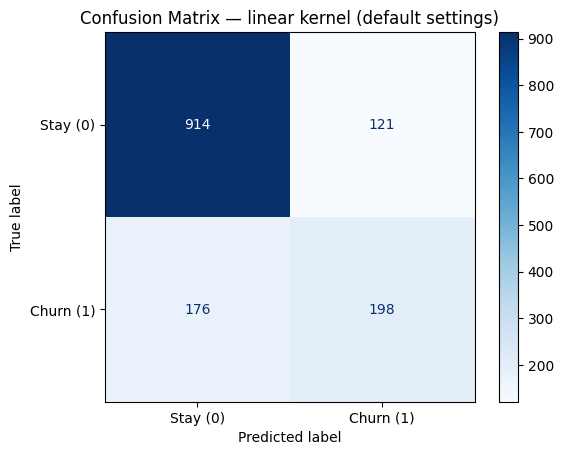

In [7]:
# YOUR CODE HERE — confusion matrix for the best kernel
from sklearn.metrics import ConfusionMatrixDisplay

best_kernel = kernel_df['F1-score'].idxmax()
print("Best kernel on F1:", best_kernel)

ConfusionMatrixDisplay.from_estimator(
    kernel_models[best_kernel], X_test_s, y_test,
    display_labels=['Stay (0)', 'Churn (1)'], cmap='Blues')
plt.title(f"Confusion Matrix — {best_kernel} kernel (default settings)")
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:*
The linear kernel had the best F1 at 0.5714, then RBF at 0.5562, then polynomial at 0.5395. It was a bit surprising, because in class RBF is usually shown as the more powerful kernel. But it makes sense for this data: most columns are simple yes/no dummies and churn is mostly driven by a few clear things (contract type, tenure, charges), so a straight boundary already does a good job. Also, RBF and poly were run with default settings, so they have not had a fair chance yet. RBF did get the highest accuracy (0.7928) and highest precision (0.6444), so the gap is small.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:*
The polynomial kernel used the most support vectors (2,739), then RBF (2,661), then linear (2,569). That is almost half of the 5,634 training rows for every kernel. A high count means lots of points are sitting on or inside the margin, i.e. the classes overlap a lot and the model needs many points to describe its boundary. For poly, it suggests a more complicated (wigglier) boundary that is not actually helping it has the most support vectors but the lowest F1.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:*
I will carry forward RBF. Linear only beats it by 0.015 F1(0.5714 vs 0.5562), and RBF was running on untuned defaults while already giving the best accuracy (0.7928) and precision (0.6444). RBF has two knobs (C and gamma) that can move it a lot, and with a small gamma it can act almost like a linear model anyway, so tuning it can only match or beat linear. Poly is dropped: lowest F1 (0.5395), lowest recall (0.4652) and the most support vectors.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [ ]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_s)  

print("Explained variance per component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance (2 PCs):", round(pca.explained_variance_ratio_.sum(), 4))

Explained variance per component: [0.3325 0.1198]
Total explained variance (2 PCs): 0.4523


In [9]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
C_values = [0.01, 1, 100]
pca_models = {}
for C in C_values:
    m = SVC(kernel='rbf', C=C, random_state=42)
    m.fit(X_train_pca, y_train)
    pca_models[C] = m
    print(f"C = {C:<6} | support vectors = {m.support_.shape[0]:<5} | "
          f"train accuracy (2-D) = {m.score(X_train_pca, y_train):.4f}")

C = 0.01   | support vectors = 2997  | train accuracy (2-D) = 0.7346


C = 1      | support vectors = 2659  | train accuracy (2-D) = 0.7792


C = 100    | support vectors = 2631  | train accuracy (2-D) = 0.7813


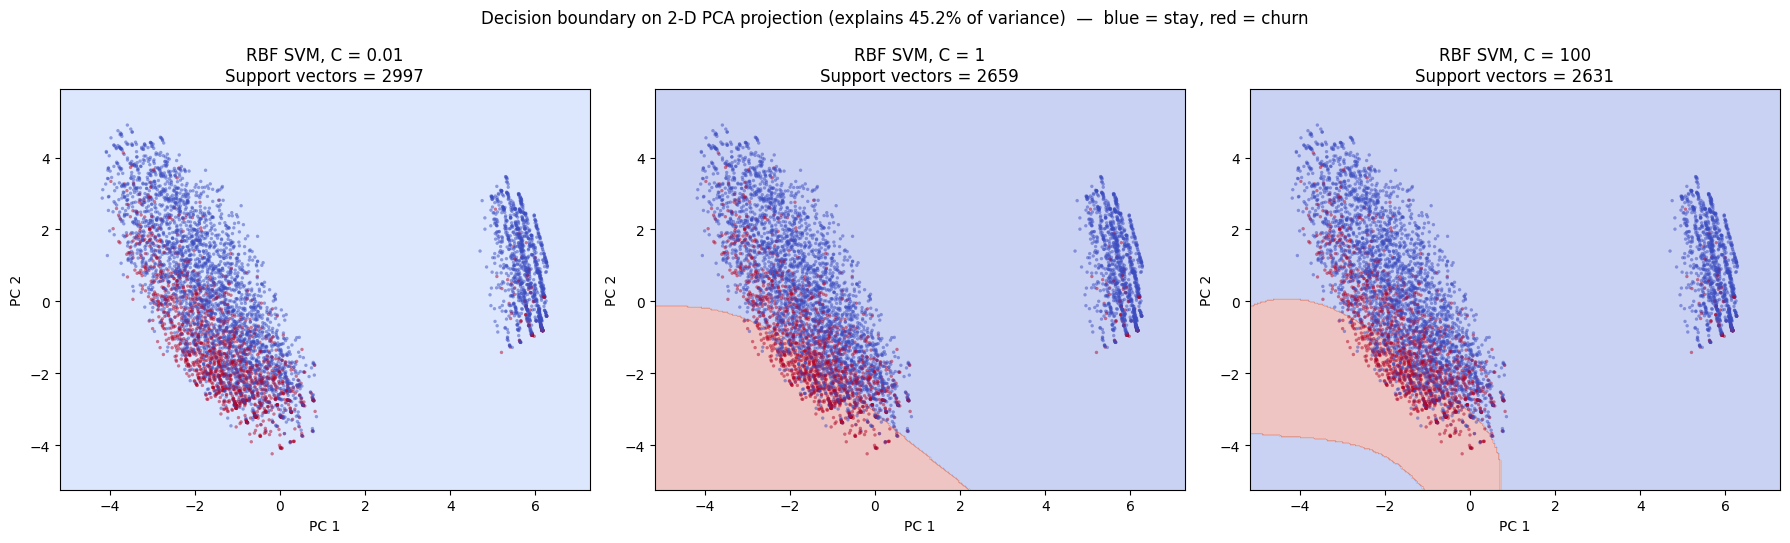

In [ ]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, C in zip(axes, C_values):
    m = pca_models[C]
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm',
               s=6, alpha=0.5, edgecolors='none')
    ax.set_title(f"RBF SVM, C = {C}\nSupport vectors = {m.support_.shape[0]}")
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
plt.suptitle(f"Decision boundary on 2-D PCA projection "
             f"(explains {pca.explained_variance_ratio_.sum():.1%} of variance)  —  blue = stay, red = churn")
plt.tight_layout()
plt.show()

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:*
At C = 0.01 there is no boundary at all  the whole plot is blue, so the model says "no churn" for everyone. At C = 1 a smooth curved red region appears in the bottom-left, where most churners are. At C = 100 the red region gets tighter and bends more, and it even curls back at the very bottom-left corner, where there is hardly any data. So as C grows, the boundary goes from flat → smooth curve → tighter and more bent.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:*
Support vectors went down as C went up: 2,997 → 2,659 → 2,631. This matches the theory. A small C means mistakes are cheap, so the margin is wide and lots of points fall inside it and become support vectors. A large C punishes mistakes heavily, so the margin gets narrower and fewer points end up inside it. The drop from C=1 to C=100 is small because in 2-D the classes overlap so much that many points stay on the wrong side no matter what.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:*
Underfitting: C = 0.01. It predicts everyone as "stay". Its training accuracy (0.7346) is basically just the share of non-churners (73.5%), so it learned nothing. Starting to overfit: C = 100.Its training accuracy (0.7813) is only a tiny bit higher than C=1 (0.7792), but the boundary has an odd bent shape in the empty bottom-left corner it is shaping itself around a few points instead of the general pattern. C = 1 looks like the healthy middle: a simple, smooth curve around the churn-heavy area.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:*
The two PCA components only keep 45.2%of the variance (33.3% + 12.0%), so more than half of the information is thrown away. Points that look mixed up in 2-D may be well separated in the real 30-D space, and the other way round. The real model also uses all 30 features and a different gamma scale, so its boundary, support vectors and best C can be quite different. The plot might make us think churn is "impossible" to separate, or that C matters more or less than it really does. It is only a picture to build intuition, not the actual model.

**What the plot shows:** the data splits into two big groups along PC 1 (the right-hand group is almost all blue likely customers without internet service). Churners (red) cluster in the lower-left part of the big group, and a larger C lets the model draw a tighter red area around them.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [11]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C':     [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1]
}

start = time.time()
gs = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid,
                  cv=5, scoring='f1', n_jobs=-1)
gs.fit(X_train_s, y_train)
print(f"Grid search time: {time.time() - start:.1f} s")
print("Best params :", gs.best_params_)
print("Best CV F1  :", round(gs.best_score_, 4))

Grid search time: 41.3 s
Best params : {'C': 100, 'gamma': 0.01}
Best CV F1  : 0.5877


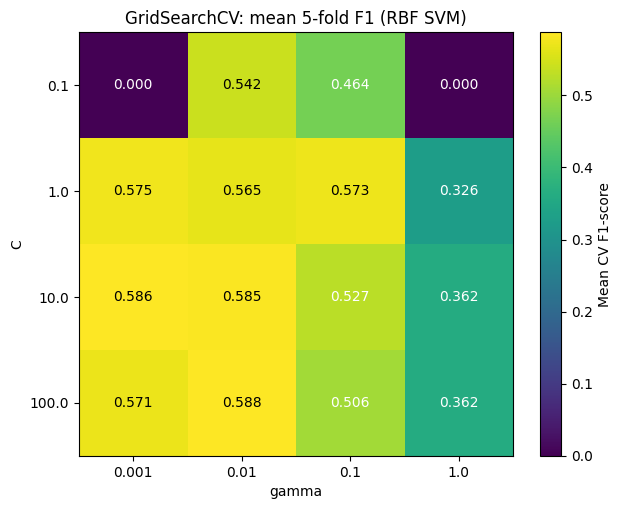

param_gamma,0.001,0.010,0.100,1.000
param_C,,,,
0.1,0.0000,0.5417,0.4640,0.0000
1.0,0.5746,0.5650,0.5734,0.3261
10.0,0.5857,0.5853,0.5266,0.3621
100.0,0.5710,0.5877,0.5060,0.3621


In [12]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
results = pd.DataFrame(gs.cv_results_)
heat = results.pivot(index='param_C', columns='param_gamma', values='mean_test_score')

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(heat.values, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(heat.index)));   ax.set_yticklabels(heat.index)
ax.set_xlabel('gamma'); ax.set_ylabel('C')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.3f}", ha='center', va='center',
                color='white' if heat.values[i, j] < heat.values.max() - 0.05 else 'black')
plt.colorbar(im, label='Mean CV F1-score')
plt.title('GridSearchCV: mean 5-fold F1 (RBF SVM)')
plt.show()
heat.round(4)

Tuned RBF SVM on TEST set
Accuracy : 0.7786
Precision: 0.5939
Recall   : 0.5241
F1-score : 0.5568

CV F1 = 0.5877  vs  Test F1 = 0.5568
Untuned RBF (Part 2) test F1 = 0.5562


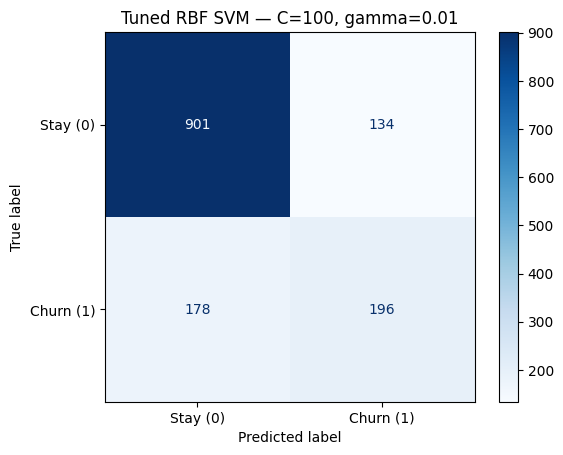

In [ ]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
from sklearn.metrics import classification_report

best_svm = gs.best_estimator_ 
y_pred_best = best_svm.predict(X_test_s)

print("Tuned RBF SVM on TEST set")
print(f"Accuracy : {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_best):.4f}")
print(f"\nCV F1 = {gs.best_score_:.4f}  vs  Test F1 = {f1_score(y_test, y_pred_best):.4f}")
print(f"Untuned RBF (Part 2) test F1 = {kernel_df.loc['rbf', 'F1-score']:.4f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best,
    display_labels=['Stay (0)', 'Churn (1)'], cmap='Blues')
plt.title(f"Tuned RBF SVM — C={gs.best_params_['C']}, gamma={gs.best_params_['gamma']}")
plt.show()

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:*
The best combination was C = 100 and gamma = 0.01, with a cross-validated F1 of 0.5877.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:*
There is no single sharp peak  there is a wide good zone. Everything with C ≥ 1 and gamma between 0.001 and 0.1 scores roughly 0.51–0.59, and several cells are within 0.01 of the best (e.g. C=10, gamma=0.001 → 0.5857; C=10, gamma=0.01 → 0.5853). The bad areas are very clear though: gamma = 1 is poor everywhere (0.33–0.36) because each point only "sees" its closest neighbours and the model overfits, and C = 0.1 with gamma 0.001 or 1 gives F1 = 0 because the model just predicts "no churn" for everyone. So the model is not very sensitive to the exact values as long as you stay out of those extreme corners.

**What the heatmap shows:** bright (good) cells form a band in the middle-left of the grid, and the right column (gamma = 1) and the top corners are dark. The best cell is only slightly brighter than its neighbours.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:*
CV F1 was 0.5877 and test F1 was 0.5568, a gap of about 0.03. That is fairly small and normal picking the best of 16 combinations always makes the CV score a little optimistic. A large gap (say 0.10 or more) would mean the chosen settings were overfitting to the training folds, or that the test set is somehow different from the training data.

**What the confusion matrix shows:** out of 374 real churners, the tuned model catches 196 and misses 178. It also wrongly flags 134 loyal customers.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:*
Honestly, not really. The tuned RBF got test F1 0.5568 vs 0.5562 for the default RBF in Part 2  almost the same. Recall went up a bit (0.4893 → 0.5241) but precision and accuracy went down (0.6444 → 0.5939, 0.7928 → 0.7786). The grid search took about 40 seconds for almost no gain. It was still useful because it showed which areas to avoid and confirmed that the defaults were already in the good zone but the real problem is class imbalance, not C/gamma.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


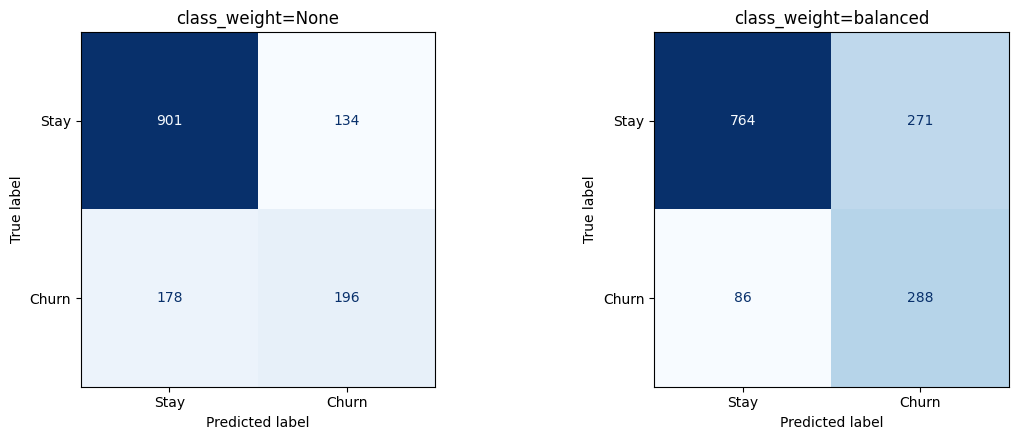

,Accuracy,Precision,Recall,F1-score
Model,,,,
class_weight=None,0.7786,0.5939,0.5241,0.5568
class_weight=balanced,0.7466,0.5152,0.7701,0.6174


In [14]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
best_C, best_gamma = gs.best_params_['C'], gs.best_params_['gamma']

# probability=True lets SVC give probability-like scores (needed for the ROC curve)
svm_default = SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight=None,
                  probability=True, random_state=42).fit(X_train_s, y_train)
svm_balanced = SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight='balanced',
                   probability=True, random_state=42).fit(X_train_s, y_train)

imb_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, m) in zip(axes, [('class_weight=None', svm_default),
                                ('class_weight=balanced', svm_balanced)]):
    p = m.predict(X_test_s)
    imb_rows.append({'Model': name,
                     'Accuracy': accuracy_score(y_test, p),
                     'Precision': precision_score(y_test, p),
                     'Recall': recall_score(y_test, p),
                     'F1-score': f1_score(y_test, p)})
    ConfusionMatrixDisplay.from_predictions(y_test, p, ax=ax, cmap='Blues',
                                            display_labels=['Stay', 'Churn'], colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

imb_df = pd.DataFrame(imb_rows).set_index('Model').round(4)
imb_df

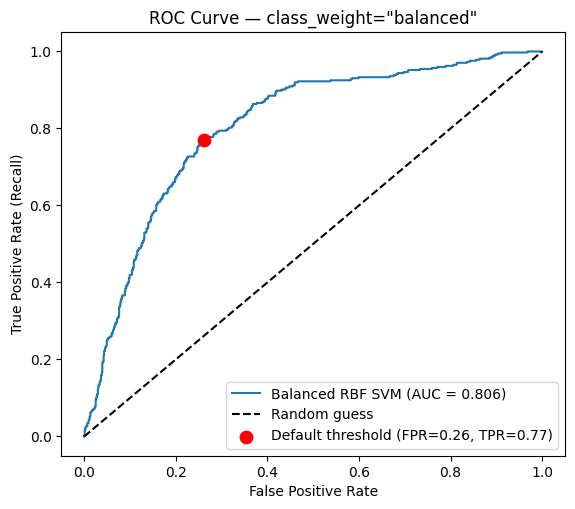

AUC (using predict_proba): 0.8058


In [ ]:
# YOUR CODE HERE — ROC or Precision-Recall curve
from sklearn.metrics import roc_curve, roc_auc_score

scores = svm_balanced.decision_function(X_test_s)       
probs  = svm_balanced.predict_proba(X_test_s)[:, 1]     

fpr, tpr, thr = roc_curve(y_test, scores)
auc = roc_auc_score(y_test, scores)

pred_default = (scores >= 0).astype(int)
tn = ((pred_default == 0) & (y_test == 0)).sum(); fp = ((pred_default == 1) & (y_test == 0)).sum()
tp = ((pred_default == 1) & (y_test == 1)).sum(); fn = ((pred_default == 0) & (y_test == 1)).sum()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr, tpr, label=f'Balanced RBF SVM (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.scatter(op_fpr, op_tpr, color='red', s=80, zorder=5,
            label=f'Default threshold (FPR={op_fpr:.2f}, TPR={op_tpr:.2f})')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve — class_weight="balanced"')
plt.legend(loc='lower right'); plt.show()
print("AUC (using predict_proba):", round(roc_auc_score(y_test, probs), 4))

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:*
With `class_weight='balanced'`:
- Recall jumped from 0.5241 → 0.7701 (+0.246). Caught churners went from 196 → 288 out of 374, and missed churners dropped from 178 → 86.
- Precision fell from 0.5939 → 0.5152 (−0.079). False alarms went up from 134 → 271.
- F1 went up from 0.5568 → 0.6174, while accuracy dropped from 0.7786 → 0.7466.

So we gave up a bit of precision and accuracy to catch a lot more churners.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:*
Missing a real churner (false negative) is more costly.When a customer leaves, the company loses all of their future monthly payments, and getting a new customer usually costs more than keeping one. A false positive only means giving a loyal customer a discount or a call they did not need, which is cheap in comparison. So I would deploy the balanced model: it catches 92 more churners at the cost of 137 extra false alarms, and saving 92 paying customers is easily worth a few cheap retention offers.

**What the ROC curve shows:** the AUC is about 0.806, so the model ranks a random churner above a random loyal customer about 81% of the time. The red dot (default threshold) sits at roughly FPR ≈ 0.26, TPR ≈ 0.77  high up the curve, which is where we want to be for catching churners. Moving the threshold along the curve would let the company trade recall for precision depending on its budget.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:*
I set probability=True in SVC(). This makes sklearn run an extra internal cross-validation and fit Platt scaling (a small logistic curve) on top of the SVM scores to turn them into 0–1 values. That makes training slower. For the ROC curve I actually used decision_function() the signed distance from the boundary because ROC only needs a ranking, not true probabilities. One thing I noticed: because Platt scaling is fitted separately, predict_proba ≥ 0.5 does not always match .predict() (they disagreed on 210 of the 1,409 test rows), so the decision score is the more reliable one for the "default threshold" point.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [ ]:
# YOUR CODE HERE — cross-model comparison table
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


dt = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

rf_gs = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                     {'n_estimators': [100, 200], 'max_depth': [6, 10, None],
                      'min_samples_leaf': [1, 5]},
                     cv=5, scoring='f1', n_jobs=-1).fit(X_train, y_train)
rf = rf_gs.best_estimator_
print("RF best params:", rf_gs.best_params_)

lr  = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
knn = KNeighborsClassifier(n_neighbors=15).fit(X_train_s, y_train)

final_models = {
    'Decision Tree (Lab 3)':        (dt,  X_test),
    'Random Forest (Lab 4, tuned)': (rf,  X_test),
    'Logistic Regression (Lab 6)':  (lr,  X_test_s),
    'KNN (Lab 6)':                  (knn, X_test_s),
    'SVM tuned (class_weight=None)':     (svm_default,  X_test_s),
    'SVM tuned (class_weight=balanced)': (svm_balanced, X_test_s),
}
comp = []
for name, (m, Xt) in final_models.items():
    p = m.predict(Xt)
    comp.append({'Model': name, 'Accuracy': accuracy_score(y_test, p),
                 'Precision': precision_score(y_test, p),
                 'Recall': recall_score(y_test, p), 'F1-score': f1_score(y_test, p)})
comparison_df = pd.DataFrame(comp).set_index('Model').round(4)
comparison_df

RF best params: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}


,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree (Lab 3),0.7942,0.6296,0.5455,0.5845
"Random Forest (Lab 4, tuned)",0.8070,0.6711,0.5348,0.5952
Logistic Regression (Lab 6),0.8070,0.6584,0.5668,0.6092
KNN (Lab 6),0.7700,0.5706,0.5401,0.5549
SVM tuned (class_weight=None),0.7786,0.5939,0.5241,0.5568
SVM tuned (class_weight=balanced),0.7466,0.5152,0.7701,0.6174


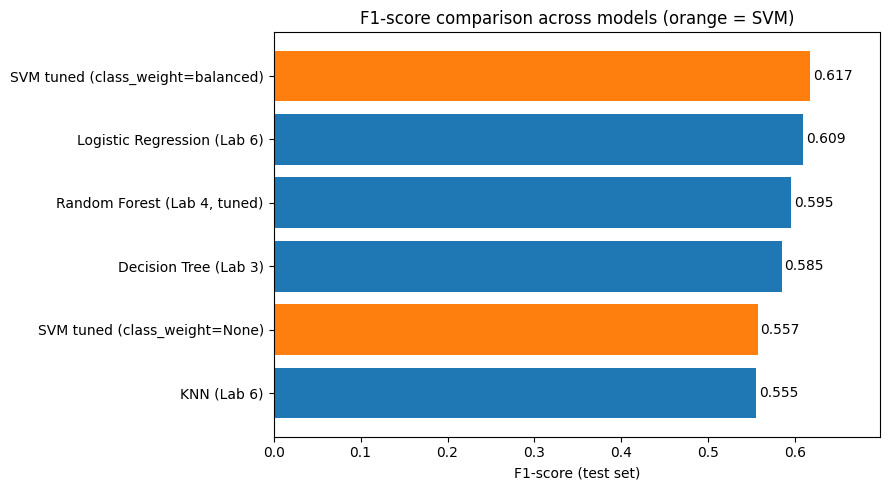

In [17]:
# YOUR CODE HERE — bar chart of F1-score across models
plot_df = comparison_df.sort_values('F1-score')
colors = ['tab:orange' if 'SVM' in n else 'tab:blue' for n in plot_df.index]

plt.figure(figsize=(9, 5))
bars = plt.barh(plot_df.index, plot_df['F1-score'], color=colors)
for b in bars:
    plt.text(b.get_width() + 0.003, b.get_y() + b.get_height() / 2,
             f"{b.get_width():.3f}", va='center')
plt.xlabel('F1-score (test set)')
plt.xlim(0, plot_df['F1-score'].max() + 0.08)
plt.title('F1-score comparison across models (orange = SVM)')
plt.tight_layout(); plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:*
The balanced SVM wins on both: highest F1 (0.6174)and highest recall (0.7701). So yes, it is the same model. Logistic Regression is a close second on F1 (0.6092) and has the best accuracy (0.8070), and Random Forest has the best precision (0.6711).

**What the bar chart shows:** all models are packed between about 0.55 and 0.62 F1. The balanced SVM is on top, LR right behind, and the plain (unbalanced) SVM and KNN are at the bottom.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:*
Only partly. The SVM grid search took about 40 seconds plus the extra probability=True fitting, while the trees and Logistic Regression train in a second or two. The plain tuned SVM (F1 0.5568) was actually worse than Decision Tree (0.5845), Random Forest (0.5952) and Logistic Regression (0.6092). The only reason SVM ends up on top is class_weight='balanced, and that trick can be used with the other models too. So the extra cost of SVM itself was not really worth it here  the balancing was what helped.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:*
I would recommend the balanced RBF SVM. It has the best F1 (0.6174) and by far the best recall (0.7701) it catches 288 of 374 churners, while the next best model on recall only catches around 212 (0.5668). Its precision (0.5152) means about half of the flagged customers are real churners, which is fine for a cheap retention offer. Its AUC of 0.806 also shows it ranks customers well. If training speed or easy explanation mattered more, a Logistic Regression with class_weight='balanced would be the next thing I would test, since it was already very close.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [18]:
# YOUR CODE HERE — generate and save svm_predictions.csv
final_model = svm_balanced

final_pred  = final_model.predict(X_test_s)
final_prob  = final_model.predict_proba(X_test_s)[:, 1]
final_score = final_model.decision_function(X_test_s)

predictions = pd.DataFrame({
    'customer_index': X_test.index,
    'true_label': y_test.values,
    'predicted_label': final_pred,
    'churn_probability': final_prob.round(4),
    'svm_decision_score': final_score.round(4)
})
predictions.to_csv('svm_predictions.csv', index=False)
print("Saved svm_predictions.csv with", len(predictions), "rows")
predictions.head(10)

Saved svm_predictions.csv with 1409 rows


,customer_index,true_label,predicted_label,churn_probability,svm_decision_score
0,437,0,0,0.0606,-1.7791
1,2280,0,1,0.6042,1.2594
2,2235,0,0,0.0402,-2.1771
3,4460,0,0,0.2548,-0.1545
4,3761,0,0,0.0390,-2.2061
5,5748,0,1,0.6119,1.2887
6,3568,0,1,0.3621,0.3181
7,2976,0,0,0.1578,-0.7250
8,5928,0,0,0.0585,-1.8135
9,1639,1,1,0.4751,0.7679


**Executive Summary**

I chose an RBF-kernel SVM (C = 100, gamma = 0.01) with class_weight=balanced as the final model for predicting customer churn. On the held-out test set it reached F1 = 0.617, recall = 0.770, precision = 0.515, accuracy = 0.747 and ROC-AUC = 0.806. It catches 288 out of 374 real churners, compared to only 196 for the same SVM without balancing. The main trade-off was giving up some precision (0.594 → 0.515) and accuracy to get a big jump in recall, because losing a customer costs the company much more than sending a retention offer to someone who was going to stay. Scaling turned out to be essential: without it the SVM did not even converge and got only 60% accuracy. Kernel choice and C/gamma tuning made little difference, while handling class imbalance made the biggest difference. One limitation is that the Decision Tree, Random Forest, LR and KNN baselines were not given class_weight='balanced, so the comparison slightly favours the SVM; a balanced Logistic Regression might perform just as well while being faster and easier to explain.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:*
How little tuning helped. I expected GridSearchCV to give a clear boost, but the tuned RBF (F1 0.5568) was basically the same as the default one (0.5562). Just switching on class_weight='balanced raised F1 by about 0.06 and recall by almost 0.25 a tiny one-line change mattered way more than 16 hyperparameter combinations.

(b) If you had one more hour, what would you try next?

*Your answer:*
I would first try class_weight='balanced' on Logistic Regression and Random Forest** to make the comparison fully fair. Then I would try moving the decision threshold using the ROC curve instead of always using the default, and some feature engineering (e.g. average charge per month of tenure, number of add-on services). I would also include class_weight inside the grid search so C and gamma are tuned for the balanced model directly.
